In [1]:
from scipy.io import loadmat
import mat73

from tqdm.notebook import tqdm

import numpy as np
import pandas as pd

from matplotlib import pyplot as plt
from matplotlib import colorbar as mbar
import seaborn as sns

from scipy.ndimage import gaussian_filter as smooth

from scipy.stats import zscore
from scipy.stats import sem
from scipy.stats import spearmanr as spearman

from scipy.stats import permutation_test

import warnings
warnings.filterwarnings('ignore')
from IPython.display import clear_output

# Definitions

In [2]:
def m_plot(input_data, colors, error_method='sem', smooth_win=0, labels=[], plot_title='', XAxisTicks=[], figure_size=(8,3)):
    '''
    Args:
        input_data:   (N,M,T) matrix of input data, (Conditions,Samples,Timepoints)
        colors:       (N,4) matrix of colors for the generated plots in [R,G,B,FaceAlpha] format,
                      where N is the number of conditions. FaceAlpha in the scale=[0-255]
        error_method: variation metric ('sem' & 'std')
        smooth_win:   smoothing window
        
        labels:       (N,) list of labels for the generated plots, where N is the number of conditions
        plot_title:   title of the generated plot
        XAxisTicks:   (N,) vaetor of XAxisTicks
        figure_size:  two-item tuple containing width and height of the figure
    Returns:
        none
    '''

    colors = np.array(colors) / np.array(255)
    if not labels: labels=['']*len(input_data)
    XAxisTicks = np.array(XAxisTicks)
    if XAxisTicks.size==0: XAxisTicks = np.arange(0,input_data[0].shape[1])
    
    plt.figure(figsize=figure_size)
    for i,Cond in enumerate(input_data):
        data_ave = smooth(np.nanmean(Cond, axis=0), smooth_win)
        data_std = smooth(np.nanstd(Cond, axis=0), smooth_win)
        
        if error_method=='sem':
            error_up  = data_ave + (data_std / np.sqrt(Cond.shape[0]))
            error_low = data_ave - (data_std / np.sqrt(Cond.shape[0]))
        elif error_method=='std':
            error_up  = data_ave + data_std
            error_low = data_ave - data_std

        plt.fill_between(XAxisTicks, error_up, error_low, color=colors[i], label='_nolegend_')
        plt.plot(XAxisTicks, data_ave, color=colors[i,:3], lw=figure_size[0]*.5, label=labels[i])
    
    ylim = plt.ylim()
    plt.legend(frameon=False, fontsize=figure_size[0]*1.5)
    plt.title(plot_title, fontsize=figure_size[0]*1.8)
    # plt.rcParams.update({'font.size': figure_size[0]*.5})
    plt.tight_layout()


def rand_idx_gen(cyles, cat_inds, stim_num, replacement=False):
    '''
    Args:
        cyles:       number repetitions or cycles
        cat_inds:    (N,) list of indices in each category/condition, where N is the number of categories/conditions,
                     and each item in the list is a np.array of indices for that category/condition.
        stim_num:    number of samples for each category/condition
        replacement: if True, sampling will be with replacement
    Returns:
        idx_rand: (N,M) np.array of the generated random indices, (cyles,cat_inds*stim_num)
    '''
    np.random.seed(15)
    idx_rand = []

    for iCycle in range(cyles):
        tmp_rand_tdx = []
        for i,iCat in enumerate(cat_inds):
            tmp_rand_tdx = np.concatenate((tmp_rand_tdx, iCat[np.random.choice(iCat.shape[0], stim_num, replace=replacement)]), axis=0)
        idx_rand.append(tmp_rand_tdx)

    return np.array(idx_rand).astype('int')


def comp_permute_p(vec1, vec2, permute_reps=100001):
    '''
    Args:
        vec1:         (N,) vector of data 1st distribution (Samples,)
        vec2:         (N,) vector of data 2nd distribution (Samples,)
        permute_reps: number of repetitions for the permutation process
    Returns:
        p_val: two-tailed p-value of the permutation process for [vec2 - vec1]
    '''

    vec1 = vec1[np.where((~np.isnan(vec1)))[0]]
    vec2 = vec2[np.where((~np.isnan(vec2)))[0]]

    def tmp_test_stat(x, y, axis):
        return np.nanmean(x, axis=axis) - np.nanmean(y, axis=axis)
    
    p_val = np.nan
    p_val = permutation_test(data=(vec2, vec1), statistic=tmp_test_stat, vectorized=True, axis=0, random_state=15, n_resamples=permute_reps).pvalue

    return p_val


def OutlierRemover(input_data):
    '''
    Args:
        input_data: (N,) vector of input data
    Returns:
        (M,) vector of data with outliers removed
    '''
    
    return np.array(input_data[abs(zscore(input_data))<3])

def compute_dprime(data1, data2):
    '''
    Args:
        data1: data for condition 1, shape (N,)
        data2: data for condition 2, shape (N,)
    Returns:
        d-prime value between the two data distributions, for data1-data2
    '''
    
    return (np.nanmean(data1) - np.nanmean(data2)) / np.sqrt(.5 * (np.nanvar(data1) + np.nanvar(data2)) )


In [3]:
"""
Functions for calculating the statistical significant differences between two dependent or independent correlation
coefficients.
The Fisher and Steiger method is adopted from the R package http://personality-project.org/r/html/paired.r.html
and is described in detail in the book 'Statistical Methods for Psychology'
The Zou method is adopted from http://seriousstats.wordpress.com/2012/02/05/comparing-correlations/
Credit goes to the authors of above mentioned packages!

Author: Philipp Singer (www.philippsinger.info)
"""

from __future__ import division
import numpy as np
from scipy.stats import t, norm
from math import atanh, pow
from numpy import tanh

def rz_ci(r, n, conf_level = 0.95):
    zr_se = pow(1/(n - 3), .5)
    moe = norm.ppf(1 - (1 - conf_level)/float(2)) * zr_se
    zu = atanh(r) + moe
    zl = atanh(r) - moe
    return tanh((zl, zu))

def rho_rxy_rxz(rxy, rxz, ryz):
    num = (ryz-1/2.*rxy*rxz)*(1-pow(rxy,2)-pow(rxz,2)-pow(ryz,2))+pow(ryz,3)
    den = (1 - pow(rxy,2)) * (1 - pow(rxz,2))
    return num/float(den)

def dependent_corr(xy, xz, yz, n, twotailed=True, conf_level=0.95, method='steiger'):
    """
    Calculates the statistic significance between two dependent correlation coefficients
    @param xy: correlation coefficient between x and y
    @param xz: correlation coefficient between x and z
    @param yz: correlation coefficient between y and z
    @param n: number of elements in x, y and z
    @param twotailed: whether to calculate a one or two tailed test, only works for 'steiger' method
    @param conf_level: confidence level, only works for 'zou' method
    @param method: defines the method uses, 'steiger' or 'zou'
    @return: t and p-val
    """
    if method == 'steiger':
        d = xy - xz
        determin = 1 - xy * xy - xz * xz - yz * yz + 2 * xy * xz * yz
        av = (xy + xz)/2
        cube = (1 - yz) * (1 - yz) * (1 - yz)

        t2 = d * np.sqrt((n - 1) * (1 + yz)/(((2 * (n - 1)/(n - 3)) * determin + av * av * cube)))
        p = 1 - t.cdf(abs(t2), n - 3)

        if twotailed:
            p *= 2

        return t2, p
    elif method == 'zou':
        L1 = rz_ci(xy, n, conf_level=conf_level)[0]
        U1 = rz_ci(xy, n, conf_level=conf_level)[1]
        L2 = rz_ci(xz, n, conf_level=conf_level)[0]
        U2 = rz_ci(xz, n, conf_level=conf_level)[1]
        rho_r12_r13 = rho_rxy_rxz(xy, xz, yz)
        lower = xy - xz - pow((pow((xy - L1), 2) + pow((U2 - xz), 2) - 2 * rho_r12_r13 * (xy - L1) * (U2 - xz)), 0.5)
        upper = xy - xz + pow((pow((U1 - xy), 2) + pow((xz - L2), 2) - 2 * rho_r12_r13 * (U1 - xy) * (xz - L2)), 0.5)
        return lower, upper
    else:
        raise Exception('Wrong method!')

def independent_corr(xy, ab, n, n2 = None, twotailed=True, conf_level=0.95, method='fisher'):
    """
    Calculates the statistic significance between two independent correlation coefficients
    @param xy: correlation coefficient between x and y
    @param xz: correlation coefficient between a and b
    @param n: number of elements in xy
    @param n2: number of elements in ab (if distinct from n)
    @param twotailed: whether to calculate a one or two tailed test, only works for 'fisher' method
    @param conf_level: confidence level, only works for 'zou' method
    @param method: defines the method uses, 'fisher' or 'zou'
    @return: z and p-val
    """

    if method == 'fisher':
        xy_z = 0.5 * np.log((1 + xy)/(1 - xy))
        ab_z = 0.5 * np.log((1 + ab)/(1 - ab))
        if n2 is None:
            n2 = n

        se_diff_r = np.sqrt(1/(n - 3) + 1/(n2 - 3))
        diff = xy_z - ab_z
        z = abs(diff / se_diff_r)
        p = (1 - norm.cdf(z))
        if twotailed:
            p *= 2

        return z, p
    elif method == 'zou':
        L1 = rz_ci(xy, n, conf_level=conf_level)[0]
        U1 = rz_ci(xy, n, conf_level=conf_level)[1]
        L2 = rz_ci(ab, n2, conf_level=conf_level)[0]
        U2 = rz_ci(ab, n2, conf_level=conf_level)[1]
        lower = xy - ab - pow((pow((xy - L1), 2) + pow((U2 - ab), 2)), 0.5)
        upper = xy - ab + pow((pow((U1 - xy), 2) + pow((ab - L2), 2)), 0.5)
        return lower, upper
    else:
        raise Exception('Wrong method!')



# Load Data


In [97]:
FigDir = '../Results/figs_power/'

tmp_FileDir = '../Results/results/YMT_Power_v01_zscore.mat'
tmp_File = mat73.loadmat(tmp_FileDir)

chn_ob, chn_mpfc = 0, 1
regions = ['OB', 'mPFC']

base_level = 0

sig_thresh_1, sig_thresh_2 = .05, .001

# color
color_b, color_w, color_c = [100, 100, 100, 80], [222, 49, 99, 80], [50, 142, 110, 80]
color_b_n, color_w_n, color_c_n = np.array(color_b[:3])/255, np.array(color_w[:3])/255, np.array(color_c[:3])/255

freqs = tmp_File['ff']
idx_band_delta = np.where((freqs<=4))[0]
idx_band_theta = np.where((freqs>4) & (freqs<=12))[0]
idx_band_beta = np.where((freqs>12))[0]

power_b = tmp_File['baseline_correcected_power_baseline']
power_w = tmp_File['baseline_correcected_power_wrong']
power_c = tmp_File['baseline_correcected_power_correct']

power_wc = np.concatenate((power_w,power_c), axis=1)
idx_wc = np.concatenate((np.ones(power_w.shape[1])*1,np.ones(power_c.shape[1])*2), axis=0)
cat_inds_wc = [np.where(idx_wc==1)[0],np.where(idx_wc==2)[0]]

# parameters
trn_por = .4
base_level = 0
cycle_num = 50
tr_num = 40
min_tr = 10
tr_num_step = 5
sampsz_cor = np.arange(min_tr,(2*tr_num)-min_tr+1,tr_num_step)

rand_idx_wc = np.zeros((sampsz_cor.shape[0],cycle_num,2*tr_num))
for i_sampsz_c,sampsz_c in enumerate(sampsz_cor):
    sampsz_w = (2 * tr_num) - sampsz_c
    tmp_rand_w = rand_idx_gen(cycle_num, [np.where(idx_wc==1)[0]], sampsz_w, replacement=False)
    tmp_rand_c = rand_idx_gen(cycle_num, [np.where(idx_wc==2)[0]], sampsz_c, replacement=False)
    rand_idx_wc[i_sampsz_c] = np.concatenate((tmp_rand_w, tmp_rand_c), axis=1)


# Power Correlation

In [85]:
conv2nan = 0

power_corr_b_r = np.zeros((freqs.shape[0],freqs.shape[0])) * np.nan
power_corr_w_r, power_corr_c_r = np.copy(power_corr_b_r), np.copy(power_corr_b_r)
power_corr_b_p, power_corr_w_p, power_corr_c_p = np.copy(power_corr_b_r), np.copy(power_corr_b_r), np.copy(power_corr_b_r)

for ifreq_1 in tqdm(range(freqs.shape[0])):
    for ifreq_2 in range(freqs.shape[0]):
        power_corr_b_r[ifreq_1,ifreq_2], power_corr_b_p[ifreq_1,ifreq_2] = spearman(power_b[chn_ob,:,ifreq_1], power_b[chn_mpfc,:,ifreq_2])
        power_corr_w_r[ifreq_1,ifreq_2], power_corr_w_p[ifreq_1,ifreq_2] = spearman(power_w[chn_ob,:,ifreq_1], power_w[chn_mpfc,:,ifreq_2])
        power_corr_c_r[ifreq_1,ifreq_2], power_corr_c_p[ifreq_1,ifreq_2] = spearman(power_c[chn_ob,:,ifreq_1], power_c[chn_mpfc,:,ifreq_2])

if conv2nan==0:
    power_corr_b_r = power_corr_b_r * (power_corr_b_p<.05)
    power_corr_w_r = power_corr_w_r * (power_corr_w_p<.05)
    power_corr_c_r = power_corr_c_r * (power_corr_c_p<.05)
elif conv2nan==1:
    power_corr_b_r[power_corr_b_p>.05] = np.nan
    power_corr_w_r[power_corr_w_p>.05] = np.nan
    power_corr_c_r[power_corr_c_p>.05] = np.nan


  0%|          | 0/146 [00:00<?, ?it/s]

In [99]:
pval_wb = np.zeros((freqs.shape[0],freqs.shape[0])) * np.nan
pval_cb, pval_cw = np.copy(pval_wb), np.copy(pval_wb)

for ifreq_1 in tqdm(range(freqs.shape[0])):
    for ifreq_2 in range(freqs.shape[0]):
        h_tmpcorr = independent_corr(power_corr_w_r[ifreq_1,ifreq_2], power_corr_b_r[ifreq_1,ifreq_2], power_w.shape[1], n2=power_b.shape[1])[1]<.05
        if (h_tmpcorr) & (power_corr_w_r[ifreq_1,ifreq_2] > power_corr_b_r[ifreq_1,ifreq_2]):
            pval_wb[ifreq_1,ifreq_2] = 1
        elif h_tmpcorr==0:
            pval_wb[ifreq_1,ifreq_2] = 0
        elif (h_tmpcorr) & (power_corr_w_r[ifreq_1,ifreq_2] < power_corr_b_r[ifreq_1,ifreq_2]):
            pval_wb[ifreq_1,ifreq_2] = -1
        
        h_tmpcorr = independent_corr(power_corr_c_r[ifreq_1,ifreq_2], power_corr_b_r[ifreq_1,ifreq_2], power_c.shape[1], n2=power_b.shape[1])[1]<.05
        if (h_tmpcorr) & (power_corr_c_r[ifreq_1,ifreq_2] > power_corr_b_r[ifreq_1,ifreq_2]):
            pval_cb[ifreq_1,ifreq_2] = 1
        elif h_tmpcorr==0:
            pval_cb[ifreq_1,ifreq_2] = 0
        elif (h_tmpcorr) & (power_corr_c_r[ifreq_1,ifreq_2] < power_corr_b_r[ifreq_1,ifreq_2]):
            pval_cb[ifreq_1,ifreq_2] = -1
        
        h_tmpcorr = independent_corr(power_corr_c_r[ifreq_1,ifreq_2], power_corr_w_r[ifreq_1,ifreq_2], power_c.shape[1], n2=power_w.shape[1])[1]<.05
        if (h_tmpcorr) & (power_corr_c_r[ifreq_1,ifreq_2] > power_corr_w_r[ifreq_1,ifreq_2]):
            pval_cw[ifreq_1,ifreq_2] = 1
        elif h_tmpcorr==0:
            pval_cw[ifreq_1,ifreq_2] = 0
        elif (h_tmpcorr) & (power_corr_c_r[ifreq_1,ifreq_2] < power_corr_w_r[ifreq_1,ifreq_2]):
            pval_cw[ifreq_1,ifreq_2] = -1


  0%|          | 0/146 [00:00<?, ?it/s]

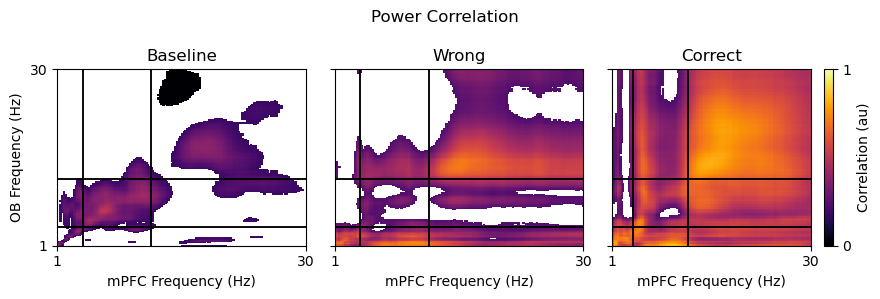

In [ ]:
fig_sz = np.array((9,3)) * 1
plot_xylim = [min(freqs), max(freqs)]
plot_xyticks = [min(freqs), max(freqs)] #[min(freqs), 4, 12, max(freqs)]
plot_line_color = [0,0,0]
plot_line_width = fig_sz[0]*.15
plot_clim = [0, 1]
colormap = 'inferno'
save_fig = 0

fig, axs = plt.subplots(figsize=fig_sz, ncols=3, nrows=1, sharex=True, sharey=True)

axs[0].pcolor(freqs, freqs, power_corr_b_r, cmap=colormap, rasterized=True, clim=plot_clim)
axs[0].set_xlim(plot_xylim)
axs[0].set_xticks(plot_xyticks)
axs[0].set_xlabel('mPFC Frequency (Hz)')
axs[0].set_ylim(plot_xylim)
axs[0].set_yticks(plot_xyticks)
axs[0].set_ylabel('OB Frequency (Hz)')
axs[0].set_title('Baseline')
axs[0].axvline(4, color=plot_line_color, lw=plot_line_width)
axs[0].axvline(12, color=plot_line_color, lw=plot_line_width)
axs[0].axhline(4, color=plot_line_color, lw=plot_line_width)
axs[0].axhline(12, color=plot_line_color, lw=plot_line_width)

axs[1].pcolor(freqs, freqs, power_corr_w_r, cmap=colormap, rasterized=True, clim=plot_clim)
axs[1].set_xlabel('mPFC Frequency (Hz)')
axs[1].set_title('Wrong')
axs[1].axvline(4, color=plot_line_color, lw=plot_line_width)
axs[1].axvline(12, color=plot_line_color, lw=plot_line_width)
axs[1].axhline(4, color=plot_line_color, lw=plot_line_width)
axs[1].axhline(12, color=plot_line_color, lw=plot_line_width)

ax2 = axs[2].pcolor(freqs, freqs, power_corr_c_r, cmap=colormap, rasterized=True, clim=plot_clim)
axs[2].set_xlabel('mPFC Frequency (Hz)')
axs[2].set_title('Correct')
axs[2].axvline(4, color=plot_line_color, lw=plot_line_width)
axs[2].axvline(12, color=plot_line_color, lw=plot_line_width)
axs[2].axhline(4, color=plot_line_color, lw=plot_line_width)
axs[2].axhline(12, color=plot_line_color, lw=plot_line_width)

fig.colorbar(mappable=ax2, ticks=plot_clim, label='Correlation (au)')
plt.suptitle(f'Power Correlation')
plt.tight_layout()

if save_fig: plt.savefig(f'{FigDir}powercorr_all.svg')

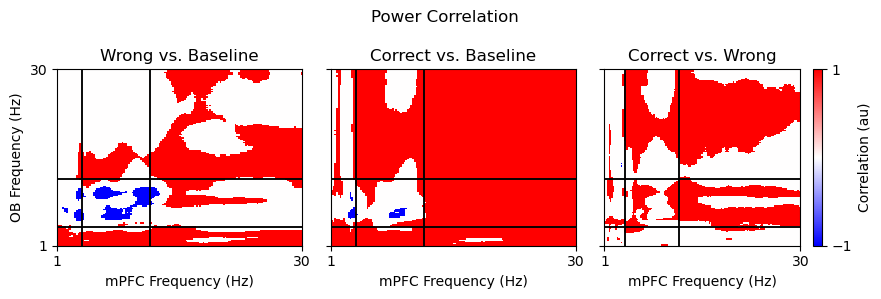

In [117]:
fig_sz = np.array((9,3)) * 1
plot_xylim = [min(freqs), max(freqs)]
plot_xyticks = [min(freqs), max(freqs)] #[min(freqs), 4, 12, max(freqs)]
plot_line_color = [0,0,0]
plot_line_width = fig_sz[0]*.15
plot_clim = [-1, 1]
# colormap = 'Set1'
colormap = 'bwr'
save_fig = 0

fig, axs = plt.subplots(figsize=fig_sz, ncols=3, nrows=1, sharex=True, sharey=True)

axs[0].pcolor(freqs, freqs, pval_wb, cmap=colormap, rasterized=True, clim=plot_clim)
axs[0].set_xlim(plot_xylim)
axs[0].set_xticks(plot_xyticks)
axs[0].set_xlabel('mPFC Frequency (Hz)')
axs[0].set_ylim(plot_xylim)
axs[0].set_yticks(plot_xyticks)
axs[0].set_ylabel('OB Frequency (Hz)')
axs[0].set_title('Wrong vs. Baseline')
axs[0].axvline(4, color=plot_line_color, lw=plot_line_width)
axs[0].axvline(12, color=plot_line_color, lw=plot_line_width)
axs[0].axhline(4, color=plot_line_color, lw=plot_line_width)
axs[0].axhline(12, color=plot_line_color, lw=plot_line_width)

axs[1].pcolor(freqs, freqs, pval_cb, cmap=colormap, rasterized=True, clim=plot_clim)
axs[1].set_xlabel('mPFC Frequency (Hz)')
axs[1].set_title('Correct vs. Baseline')
axs[1].axvline(4, color=plot_line_color, lw=plot_line_width)
axs[1].axvline(12, color=plot_line_color, lw=plot_line_width)
axs[1].axhline(4, color=plot_line_color, lw=plot_line_width)
axs[1].axhline(12, color=plot_line_color, lw=plot_line_width)

ax2 = axs[2].pcolor(freqs, freqs, pval_cw, cmap=colormap, rasterized=True, clim=plot_clim)
axs[2].set_xlabel('mPFC Frequency (Hz)')
axs[2].set_title('Correct vs. Wrong')
axs[2].axvline(4, color=plot_line_color, lw=plot_line_width)
axs[2].axvline(12, color=plot_line_color, lw=plot_line_width)
axs[2].axhline(4, color=plot_line_color, lw=plot_line_width)
axs[2].axhline(12, color=plot_line_color, lw=plot_line_width)

fig.colorbar(mappable=ax2, ticks=plot_clim, label='Correlation (au)')
plt.suptitle(f'Power Correlation')
plt.tight_layout()

if save_fig: plt.savefig(f'{FigDir}powercorr_all_stat.svg')

In [77]:
power_corr_b_r = np.zeros_like(freqs) * np.nan
power_corr_w_r, power_corr_c_r = np.copy(power_corr_b_r), np.copy(power_corr_b_r)
power_corr_b_p, power_corr_w_p, power_corr_c_p = np.copy(power_corr_b_r), np.copy(power_corr_b_r), np.copy(power_corr_b_r)

for ifreq in range(freqs.shape[0]):
    power_corr_b_r[ifreq], power_corr_b_p[ifreq] = spearman(power_b[chn_ob,:,ifreq], power_b[chn_mpfc,:,ifreq])
    power_corr_w_r[ifreq], power_corr_w_p[ifreq] = spearman(power_w[chn_ob,:,ifreq], power_w[chn_mpfc,:,ifreq])
    power_corr_c_r[ifreq], power_corr_c_p[ifreq] = spearman(power_c[chn_ob,:,ifreq], power_c[chn_mpfc,:,ifreq])

power_corr_b_r_sig = np.copy(power_corr_b_r); power_corr_b_r_sig[power_corr_b_p>.05] = np.nan
power_corr_w_r_sig = np.copy(power_corr_w_r); power_corr_w_r_sig[power_corr_w_p>.05] = np.nan
power_corr_c_r_sig = np.copy(power_corr_c_r); power_corr_c_r_sig[power_corr_c_p>.05] = np.nan


In [78]:
sigline_loc_wb, sigline_loc_cb = .98, .95

pval_wb = np.zeros_like(freqs) * np.nan
pval_cb = np.copy(pval_wb)

for ifreq in tqdm(range(freqs.shape[0])):
    pval_wb[ifreq] = independent_corr(power_corr_w_r[ifreq], power_corr_b_r[ifreq], power_w.shape[1], n2=power_b.shape[1])[1]
    pval_cb[ifreq] = independent_corr(power_corr_c_r[ifreq], power_corr_b_r[ifreq], power_c.shape[1], n2=power_b.shape[1])[1]

# create significant lines
sigtime_wb_thr1 = (pval_wb<sig_thresh_1).astype('float') * sigline_loc_wb
sigtime_wb_thr1[sigtime_wb_thr1==0] = np.nan
sigtime_wb_thr2 = (pval_wb<sig_thresh_2).astype('float') * sigline_loc_wb
sigtime_wb_thr2[sigtime_wb_thr2==0] = np.nan

sigtime_cb_thr1 = (pval_cb<sig_thresh_1).astype('float') * sigline_loc_cb
sigtime_cb_thr1[sigtime_cb_thr1==0] = np.nan
sigtime_cb_thr2 = (pval_cb<sig_thresh_2).astype('float') * sigline_loc_cb
sigtime_cb_thr2[sigtime_cb_thr2==0] = np.nan


  0%|          | 0/146 [00:00<?, ?it/s]

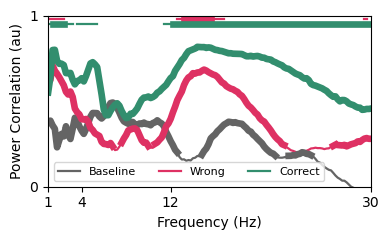

In [80]:
figure_size = np.array((4,2.5)) * 1
fig_lw_thin, fig_lw_thick = figure_size[0]*.4, figure_size[0]*1.2
plot_xlim = [1,30]
plot_xticks = [1,4,12,30]
plot_ylim = [0,1]
save_fig = 0

plt.figure(figsize=figure_size)
plt.plot(freqs, power_corr_b_r, lw=fig_lw_thin, color=color_b_n, label='Baseline')
plt.plot(freqs, power_corr_w_r, lw=fig_lw_thin, color=color_w_n, label='Wrong')
plt.plot(freqs, power_corr_c_r, lw=fig_lw_thin, color=color_c_n, label='Correct')

plt.plot(freqs, power_corr_b_r_sig, lw=fig_lw_thick, color=color_b_n, label='_nolegend_')
plt.plot(freqs, power_corr_w_r_sig, lw=fig_lw_thick, color=color_w_n, label='_nolegend_')
plt.plot(freqs, power_corr_c_r_sig, lw=fig_lw_thick, color=color_c_n, label='_nolegend_')

plt.plot(freqs, sigtime_wb_thr1, color=color_w_n, lw=fig_lw_thin)
plt.plot(freqs, sigtime_wb_thr2, color=color_w_n, lw=fig_lw_thick)

plt.plot(freqs, sigtime_cb_thr1, color=color_c_n, lw=fig_lw_thin)
plt.plot(freqs, sigtime_cb_thr2, color=color_c_n, lw=fig_lw_thick)

plt.xlabel('Frequency (Hz)')
plt.xlim(plot_xlim)
plt.xticks(plot_xticks)

plt.ylabel('Power Correlation (au)')
plt.ylim(plot_ylim)
plt.yticks(plot_ylim)

plt.legend(frameon=True, ncol=3, fontsize=figure_size[0]*2)
plt.tight_layout()
clear_output()

if save_fig: plt.savefig(f'{FigDir}powercorr_diag.svg')

# TMP

In [142]:
corrs_sequential_wc = np.zeros((rand_idx_wc.shape[0], freqs.shape[0])) * np.nan

for i_rnd,rnds in tqdm(enumerate(rand_idx_wc)):
    for ifreq in range(freqs.shape[0]):
        tmp_freq_corrs = np.zeros(cycle_num) * np.nan
        for iCycle in range(cycle_num):
            tmp_rnds = rnds[iCycle].astype('int')
            tmp_corr = spearman(power_wc[chn_ob, tmp_rnds, ifreq], power_wc[chn_mpfc, tmp_rnds, ifreq])
            tmp_freq_corrs[iCycle] = tmp_corr[0]
            # if tmp_corr[1]<.05: tmp_freq_corrs[iCycle] = tmp_corr[0]
        corrs_sequential_wc[i_rnd,ifreq] = np.nanmean(tmp_freq_corrs)


0it [00:00, ?it/s]

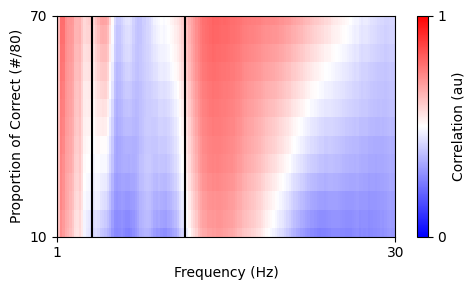

In [183]:
fig_sz = np.array((5,3)) * 1
plot_xlim = [min(freqs), max(freqs)]
plot_ylim = [min(sampsz_cor), max(sampsz_cor)]
plot_line_color = [0,0,0]
plot_line_width = fig_sz[0]*.3
plot_clim = [0, 1]
colormap = 'bwr'
save_fig = 0

plt.figure(figsize=fig_sz)
plt.pcolor(freqs, sampsz_cor, corrs_sequential_wc, cmap=colormap, rasterized=True, clim=plot_clim)
plt.colorbar(ticks=plot_clim, label='Correlation (au)')

plt.axvline(4, color=plot_line_color, lw=plot_line_width)
plt.axvline(12, color=plot_line_color, lw=plot_line_width)

plt.xlim(plot_xlim)
plt.xticks(plot_xlim)
plt.xlabel('Frequency (Hz)')

plt.ylim(plot_ylim)
plt.yticks(plot_ylim)
plt.ylabel('Proportion of Correct (#/80)')
# axs[0].set_title('Baseline')

plt.tight_layout()

if save_fig: plt.savefig(f'{FigDir}powercorr_sequential.svg')

In [151]:
corrs_sequential_wc

aaa = []
for ifreq in range(freqs.shape[0]):
    aaa.append(spearman(np.arange(corrs_sequential_wc.shape[0]), corrs_sequential_wc[:,ifreq])[0])

(1.0, 30.0)

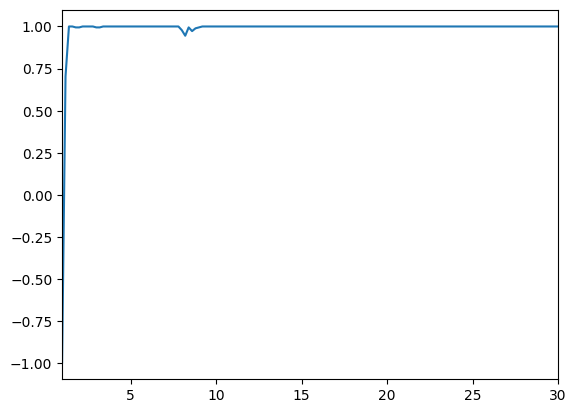

In [153]:
plt.plot(freqs, aaa)
plt.xlim([1,30])